In [23]:
%pip install tensorflow
%pip install scikit-learn
%pip install pytest


[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [24]:
import requests
import h5py
import os
import hashlib
from pathlib import Path

import tensorflow as tf
import tensorflow.keras as keras
import sklearn as sk
import matplotlib.pyplot as plt
import requests
import pytest
import numpy as np
from PIL import Image
import math
from time import perf_counter

# Fetching Dataset

The dataset is downloaded from Zenodo at runtime, rather than attached at submission.

- If Galaxy10.h5 exists, its size is checked against the expected size fetched from the request header. If it matches, download is skipped, if not, it is deleted and downloaded again. 
  
- If it doesn't exist, it is streamed in chunks to `Galaxy10.h5.part`, and the hash provided from the docs is compared during the donwload. Once the size and hash is verified, then the machine learning pipeline starts. 
  
- If verification fails, download is retried once, then the program stops with an error.


In [25]:
def stream_ingest(url, fname, hash):
    '''
    to complete
    '''
    try:
        r = requests.get(url, stream=True)
        r.raise_for_status()
    except requests.exceptions.HTTPError as e:
        return ("HTTP error occurred:", e)
    except requests.exceptions.RequestException as e:
        return "A request error occurred:", e
        
    chunk_fname = f'{fname}.part'
    fpath = Path(fname)
    fsize = int(r.headers['content-length'])
    
    hash_func = hashlib.new('sha256')
        
    # ingesting
    if not fpath.is_file() or os.path.getsize(fpath) != fsize:
        with open(chunk_fname, 'wb') as file:
            for chunk in r.iter_content(chunk_size=5_242_880):
                file.write(chunk)
                hash_func.update(chunk)
                print('Downloaded', len(chunk), "bytes")
                
            if hash_func.hexdigest().lower() == hash.lower():
                os.rename(chunk_fname, fname)
            else:
                print(f'Wrong file downloaded due to differing hash, deleting file: {chunk_fname}')
                os.remove(chunk_fname)
            
zenodo_url = 'https://zenodo.org/records/10844811/files/Galaxy10.h5'
HASH = '969A6B1CEFCC36E09FFFA86FEBD2F699A4AA19B837BA0427F01B0BC6DED458AF'.lower()
fname = 'Galaxy10.h5'       
stream_ingest(zenodo_url, fname, HASH)    

# Data Pre-Processing

HDF5 is a file format to store and manage complex data, and is what the dataset is orginally in (see appendix)

Below cells are to manipulate this file format so its readable in Python

In [26]:
def read_to_np(dataset):
    n1 = np.array(dataset)
    print(n1.shape)
    return n1

with h5py.File('Galaxy10.h5', 'r') as hf:
    for group in hf:
        print(hf[group])
        
    X_raw = read_to_np(hf['images'])
    y_raw = read_to_np(hf['ans'])
    

<HDF5 dataset "ans": shape (21785,), type "|u1">
<HDF5 dataset "images": shape (21785, 69, 69, 3), type "|u1">
(21785, 69, 69, 3)
(21785,)


X (images) has four dimensions. Looking at the shape it is composed of:
```
211785 rows (images)
    inside each: collection of 69 rows (69 pixels across)
        inside each: collection of 69 columns (69 pixels downwards)
            inside each: 3 colour channels (g, r, i band)

```


In [27]:
print('IMAGES STRUCTURE:')
print(f'dimensions- {X_raw.ndim}')
print(X_raw[:2])

print('\nLABEL STRUCTURE:')
print(f'dimensions- {y_raw.ndim}')
print(y_raw[:2])

IMAGES STRUCTURE:
dimensions- 4
[[[[16 18 15]
   [18 20 15]
   [16 17 12]
   ...
   [ 6  6  4]
   [ 9  9  7]
   [ 6  6  4]]

  [[19 24 20]
   [23 25 20]
   [17 18 13]
   ...
   [ 8  5  3]
   [10  8  6]
   [ 6  6  4]]

  [[17 22 18]
   [21 24 19]
   [17 18 13]
   ...
   [ 8  4  3]
   [11  8  7]
   [ 7  6  4]]

  ...

  [[17 14  7]
   [18 17  9]
   [15 14  7]
   ...
   [ 2  4  0]
   [ 3  5  0]
   [ 5  7  2]]

  [[22 14 11]
   [19 14  8]
   [12  9  3]
   ...
   [ 4  7  0]
   [ 6  9  2]
   [ 7 10  3]]

  [[30 12 11]
   [31 14  8]
   [24  9  2]
   ...
   [ 8 11  3]
   [11 14  6]
   [12 15  7]]]


 [[[ 1  3  0]
   [ 1  1  1]
   [ 1  1  1]
   ...
   [ 5  7  4]
   [ 3  5  2]
   [ 4  6  3]]

  [[ 1  2  0]
   [ 1  1  0]
   [ 0  0  0]
   ...
   [ 3  7  3]
   [ 2  6  2]
   [ 2  6  3]]

  [[ 3  3  1]
   [ 1  1  0]
   [ 0  0  0]
   ...
   [ 1  3  0]
   [ 2  4  1]
   [ 2  4  1]]

  ...

  [[ 5  7  4]
   [ 5  7  4]
   [ 3  5  2]
   ...
   [ 2  4  1]
   [ 1  3  1]
   [ 1  3  0]]

  [[ 4  6  3]
   [ 3  

In [28]:
unique, counts = np.unique(y_raw, return_counts=True)
print(np.asarray((unique, counts)).T)

keep = y_raw != 5
# apply to y and 
y = y_raw[keep]
shift = y >= 6
y[shift] -= 1 # relabel , -1

X_clean = X_raw[keep]
print(X_clean.shape, y.shape)

del y_raw, X_raw, unique, counts

[[   0 3461]
 [   1 6997]
 [   2 6292]
 [   3  349]
 [   4 1534]
 [   5   17]
 [   6  589]
 [   7 1121]
 [   8  906]
 [   9  519]]
(21768, 69, 69, 3) (21768,)


Removing Class 5, as it is only 17 of the cases ,and would result in noise/

In [29]:
print(np.unique(X_clean)) # 0 - 255

X = X_clean.astype(np.float32) / 255 # float32 to save space
del X_clean


[  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89
  90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
 108 109 110 111 112 113 114 115 116 117 118 119 120 121 122 123 124 125
 126 127 128 129 130 131 132 133 134 135 136 137 138 139 140 141 142 143
 144 145 146 147 148 149 150 151 152 153 154 155 156 157 158 159 160 161
 162 163 164 165 166 167 168 169 170 171 172 173 174 175 176 177 178 179
 180 181 182 183 184 185 186 187 188 189 190 191 192 193 194 195 196 197
 198 199 200 201 202 203 204 205 206 207 208 209 210 211 212 213 214 215
 216 217 218 219 220 221 222 223 224 225 226 227 228 229 230 231 232 233
 234 235 236 237 238 239 240 241 242 243 244 245 24

# Plotting

In [30]:
CLASS_NAMES = [
    'Disk, face-on, no spiral',
    'Smooth, completely round',
    'Smooth, in-between round',
    'Smooth, cigar-shaped',
    'Disk, edge-on, rounded bulge',
    'Disk, edge-on, no bulge',
    'Disk, face-on, tight spiral',
    'Disk, face-on, medium spiral',
    'Disk, face-on, loose spiral',
]

## Distribution of Classes

- Most common morphology of a galaxy is the smooth, completely round shape. For a completely random model, the accuracy would be 32% for an abitrary prediction. This is the baseline.

- Because smooth makes up around 60% of the population, F1 will eventually be evaluated to combine false positives (precision) and false negatives (recall) into one score. Macro paramrter is going to make it so each class has an equal penalisation in evaluation.

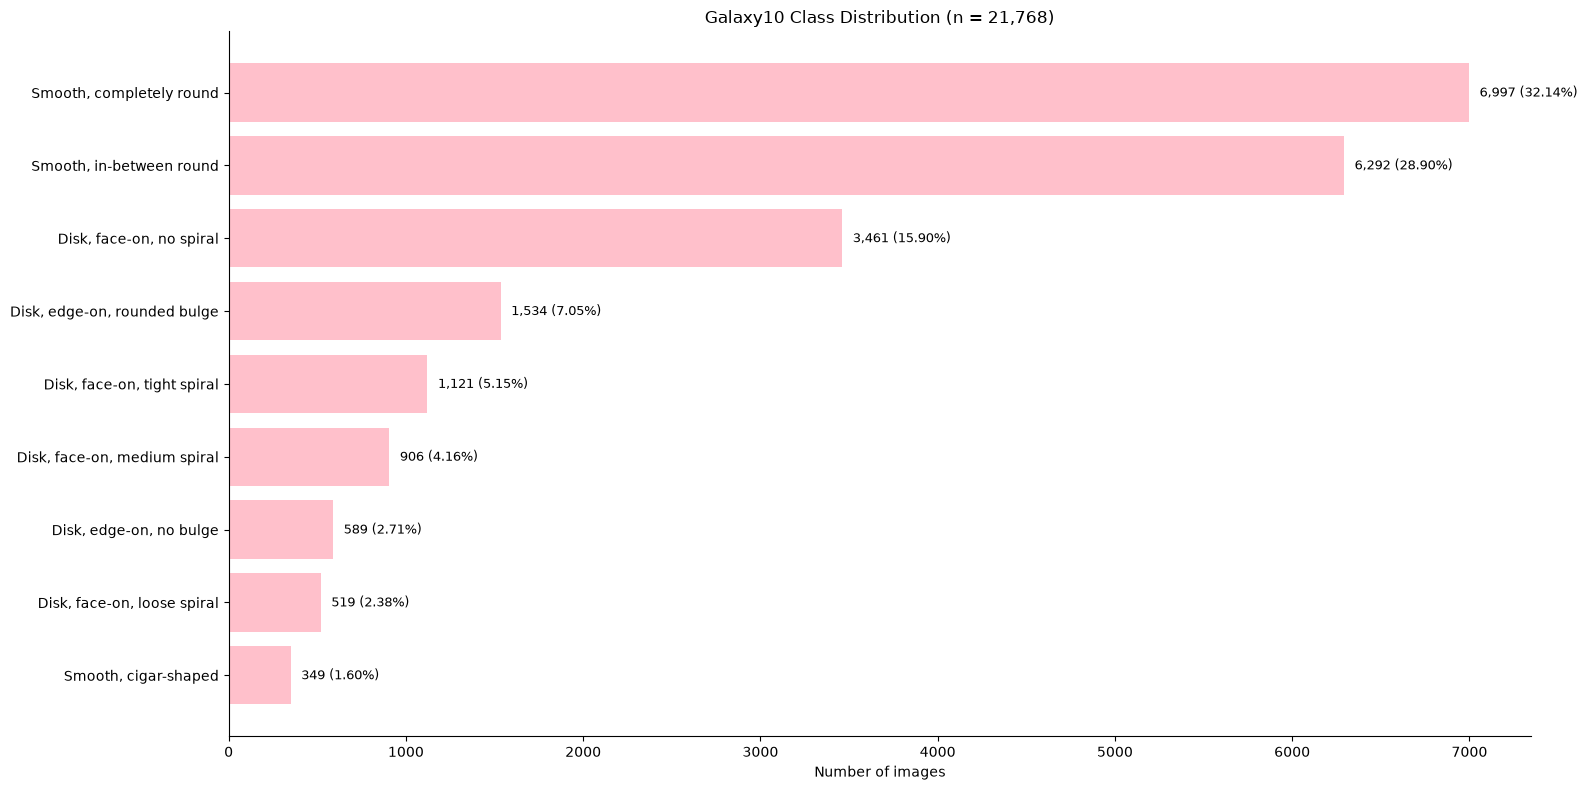

In [31]:
labels, counts = np.unique(y, return_counts=True)
order = np.argsort(counts)
pct = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(16, 8))
bars = ax.barh([CLASS_NAMES[iclass] for iclass in labels[order]], counts[order], color='pink')

for bar, count, value in zip(bars, counts[order], pct[order]):
    ax.text(bar.get_width() + 60, bar.get_y() + bar.get_height() / 2,
            f'{count:,} ({value:.2f}%)', va='center', fontsize=9)
    
ax.set_xlabel('Number of images')
ax.set_title(f'Galaxy10 Class Distribution (n = {counts.sum():,})')

ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()
             

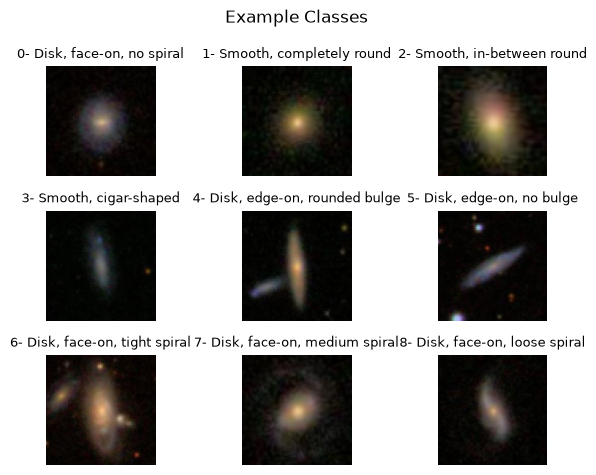

In [32]:
_, unique_y_idx = np.unique(y, return_index=True)

example_imgs = X[unique_y_idx] # index w/ an array of integers - the unique y pos (fancy indexing)

n = len(CLASS_NAMES)
ncols = 3
nrows = math.ceil(n / ncols)

fig, axs = plt.subplots(nrows, ncols, sharey=True)
axs = axs.flatten()

for i, img in enumerate(example_imgs):
    axs[i].imshow(img)
    axs[i].set_title(f'{i}- {CLASS_NAMES[i]}', fontsize=9, loc='center')
    axs[i].axis('off')
    
fig.suptitle('Example Classes')
plt.tight_layout()

del unique_y_idx, example_imgs
    

# Pre-Model (Split / Eval Functions)

## Splitting

The splitting and evaluation functions done here are meant to be universal for models.

Hence, why I am splitting on indexes, not the data, so I can apply them as needed.

70/20/10. Eval test is chosen, so as not to overfit on test when changing params.

In [33]:
idx = np.arange(len(y))

idx_rest, idx_test = sk.model_selection.train_test_split(
    idx, test_size=0.20, stratify=y, random_state=42) # 20% of the data is for testing. 


# on the 80% data, the eval size should be 10% of total.
idx_train, idx_eval = sk.model_selection.train_test_split(
    idx_rest, test_size=0.125, stratify=y[idx_rest], random_state=42 
)


# Ratios over total.
print(f'Training Proportion: {(round(len(idx_train) / len(idx) * 100))}%')
print(f'Test Proportion: {(round(len(idx_test) / len(idx) * 100))}%')
print(f'Evaluation Proportion: {(round(len(idx_eval) / len(idx) * 100))}%')

Training Proportion: 70%
Test Proportion: 20%
Evaluation Proportion: 10%


## Evaluation

Functions designed to take results from a model as an input, and evaluate it.

We are 'hiding' data from our model, which will be used to predict their classes, and compare true labels with the predicted ones. 

The metrics outputted in the model are just different eays of summarsing the comparison.

Per class:

- Precision; Of everything predicted of class x, how much of it was true. 
- Recall: Of everyting that is class x, how much of the total data did we predict for it. 
- F1: Combination of Precision and Recall. 
  - Macro F1: Average of the F1 scores- each class counts equally so ignoring small classes are punished. 

In [34]:
def evaluate(y_true, y_pred, 
             model_name=None, seed=None, split=None, CLASS_NAMES=None, time=None):
    '''
    The predicted values and the actual values in the same order are inputted. It only takes labels.
    
    The function builds a confusion matrix, and a classification report, which highlights key metrics,
    for a given model/split/seed. 
    
    Metrics of concern:
    
    - Accuracy
    - Macro F1
    - Balanced Accuracy
    '''
    labels = np.arange(len(CLASS_NAMES)) if CLASS_NAMES else None
    
    cm = sk.metrics.confusion_matrix(y_true, y_pred, labels=labels)
    
    cr = sk.metrics.classification_report(
        y_true, y_pred, 
        labels=labels, target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0
    )
    
    
    return {
        'model': model_name,
        'seed': seed,
        'split': split,
        'accuracy': cr['accuracy'],
        'macro_f1': cr['macro avg']['f1-score'],
        'balanced_accuracy': cr['macro avg']['recall'],
        'time_elapsed': time,
        'confusion_matrix': cm

    }
    

Dummy classifier to make predictions that ignore input features - baseline to compare with the models. 

In [35]:
dummy_clf = sk.dummy.DummyClassifier(strategy='most_frequent')
dummy_clf.fit(X[idx_train], y[idx_train])

y_pred = dummy_clf.predict(X[idx_eval])
floor = evaluate(y[idx_eval], y_pred, 'Dummy', 'Constant', 'eval', CLASS_NAMES)
floor

{'model': 'Dummy',
 'seed': 'Constant',
 'split': 'eval',
 'accuracy': 0.3215434083601286,
 'macro_f1': 0.054068667207353344,
 'balanced_accuracy': 0.1111111111111111,
 'time_elapsed': None,
 'confusion_matrix': array([[  0, 346,   0,   0,   0,   0,   0,   0,   0],
        [  0, 700,   0,   0,   0,   0,   0,   0,   0],
        [  0, 629,   0,   0,   0,   0,   0,   0,   0],
        [  0,  35,   0,   0,   0,   0,   0,   0,   0],
        [  0, 153,   0,   0,   0,   0,   0,   0,   0],
        [  0,  59,   0,   0,   0,   0,   0,   0,   0],
        [  0, 112,   0,   0,   0,   0,   0,   0,   0],
        [  0,  91,   0,   0,   0,   0,   0,   0,   0],
        [  0,  52,   0,   0,   0,   0,   0,   0,   0]])}

# Model 1 - Random Forest



This model is unconventional for programatically classifying images, yet it is used by humans, [such as in this dataset](https://data.galaxyzoo.org/gz_trees/gz_trees.html), to classify images via decision trees.

I wanted to see how it would fair up against traditional image classification models, like neural networks, and how questions from the original decision tree could be expressed programatically. It would also give a bit of context as to how neural networks could potentially find patterns in their hidden layers.



Random Forest Algorithm is one that uses many decision trees to make better predictions. Each tree is responsible for looking at different random parts of the data, and results are combined by majority vote. 

A decision tree is a hierarchical tree structure, which consists of internal nodes (questions) and branches (splitting of data). It aims to repeat this recursively until there are a set of leaf nodes which represents the question journey until the tree can classify an image with a degree of confidence.



In [ ]:
brightness = X.mean(axis=-1) # Collapse on the colour channel, so one grey-level value per pixel
frac = (brightness > 0.1).mean(axis=(1, 2)) # mean over the flattened 69*69 pic
print(f'Mean: {frac.mean()}',
      f'\nMin: {frac.min()}',
      f'\nMax: {frac.max()}')


71 images (as seen below) have elevated and noisy backgrounds, that are disimilar to the general pattern of a cenetered galaxy with black surrounding space (with some smaller brightened pixels representing stars, but are not useful to the galaxy classification)

See Limitations

71


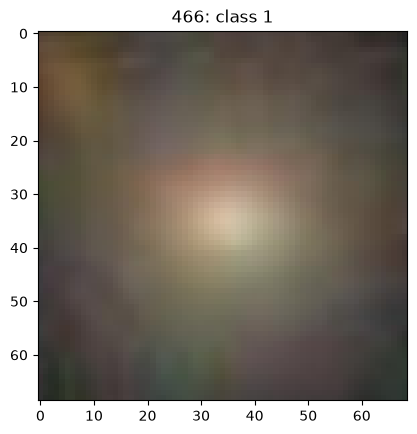

In [36]:
j = np.argmax(frac)
plt.imshow(X[j]); plt.title(f'{j}: class {y[j]}')
print((frac > 0.9).sum())
z = np.argmin(frac)

Since the galaxies in this dataset are fitted to be centered, and 26% of pixels are brighter than 0.1, the random forest should take in 25% of the total area (1190 area), which results in ≈ 35x35 crop. 

In [37]:
size = 35
c = X.shape[1] // 2  # center pixel 
a = c - size // 2 # start 
b = a + size # end 

X_crop = X[:, a:b, a:b, :]

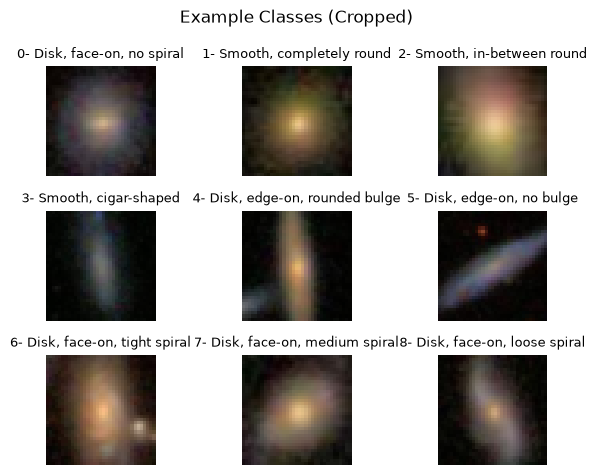

In [38]:
_, unique_y_idx = np.unique(y, return_index=True)

example_imgs = X_crop[unique_y_idx] # index w/ an array of integers - the unique y pos (fancy indexing)

n = len(CLASS_NAMES)
ncols = 3
nrows = math.ceil(n / ncols)

fig, axs = plt.subplots(nrows, ncols, sharey=True)
axs = axs.flatten()

for i, img in enumerate(example_imgs):
    axs[i].imshow(img)
    axs[i].set_title(f'{i}- {CLASS_NAMES[i]}', fontsize=9, loc='center')
    axs[i].axis('off')
    
fig.suptitle('Example Classes (Cropped)')
plt.tight_layout()

del unique_y_idx, example_imgs

From previous runs:

class weight: balanced ,results in a higher f1 score, which is our main priority, so this was chosen as the base. 

In [41]:
X_rf_crop = np.reshape(X_crop, (len(X_crop), -1))
X_rf_full = np.reshape(X, (len(X), -1))
results = []


inputs = {
    'crop': X_rf_crop,
    'full': X_rf_full,
}
models = {}
configs = {
    'RF-crop-default': {'input': 'crop', 'params': {'random_state': 42, 'n_jobs': -1}},
    'RF-crop-balanced':  {'input': 'crop', 'params': {'random_state': 42, 'n_jobs': -1, 'class_weight': 'balanced'}},
    'RF-full-balanced':  {'input': 'full', 'params': {'random_state': 42, 'n_jobs': -1, 'class_weight': 'balanced'}},

}

for name, config in configs.items():
    features = inputs[config['input']]
    params = config['params']
    rf_clf = sk.ensemble.RandomForestClassifier(**params)
    start = perf_counter()
    rf_clf.fit(features[idx_train], y[idx_train])
    end = perf_counter()
    models[name] = rf_clf
    y_pred = rf_clf.predict(features[idx_eval])
    results.append(evaluate(y[idx_eval], y_pred, name, params['random_state'], 'val', CLASS_NAMES, end-start))

1) The forest's most important features are the central pixels, as well as the a large disk or spiral which is still relatively bright. The concentrated area of bright pixels would likely classify to a smooth buldge, whereas the ring would be a disk.  

2) The dark edges are not important, and justifies the crop decision. 


To detect the galaxy's positioning, the foresth as to learn this through a flattened array, unline a CNN, where it is suited for grids. If the random forest recognises a pattenr in the top right for example, and the same shape is in the bottom left for anothr image, the forest would not know that they are the same shape. The CNN uses a sliding window to detect patterns anywhere in the grid. For this reason, I am expecting the CNN to be better especially on the spiral classes, which the RF misclassified the most

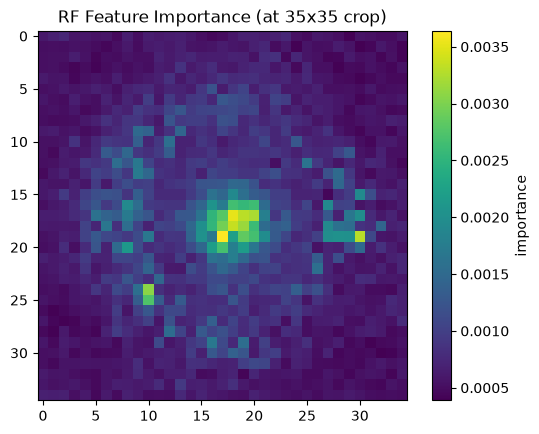

In [48]:
importances = models['RF-crop-balanced'].feature_importances_
imp_img = importances.reshape(35, 35, 3) # reshape the array back into the image
imp_map = imp_img.sum(axis=-1)

plt.imshow(imp_map)
plt.colorbar(label='importance')
plt.title('RF Feature Importance (at 35x35 crop)')
plt.show()

# Model 2 - 

In [49]:
## to do 

# probably move the crop code, to where we show example classes, so we can plot side by side. 